In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customerID:", df["customerID"].duplicated().sum())

Missing values: 0
Duplicate rows: 0
Duplicate customerID: 0


In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())
df[df["TotalCharges"].isnull()][["customerID", "tenure"]]

Missing TotalCharges: 11


,customerID,tenure
488,4472-LVYGI,0
753,3115-CZMZD,0
936,5709-LVOEQ,0
1082,4367-NUYAO,0
1340,1371-DWPAZ,0
3331,7644-OMVMY,0
3826,3213-VVOLG,0
4380,2520-SGTTA,0
5218,2923-ARZLG,0
6670,4075-WKNIU,0


In [6]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Missing now:", df["TotalCharges"].isnull().sum())

Missing now: 0


In [7]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
df[["Churn", "ChurnFlag"]].head()

,Churn,ChurnFlag
0,No,0
1,No,0
2,Yes,1
3,No,0
4,Yes,1


In [8]:
def tenure_group(t):
    if t <= 12:
        return "0-12 Months"
    elif t <= 24:
        return "13-24 Months"
    elif t <= 48:
        return "25-48 Months"
    else:
        return "49+ Months"

df["TenureGroup"] = df["tenure"].apply(tenure_group)
df["TenureGroup"].value_counts()

TenureGroup
49+ Months      2239
0-12 Months     2186
25-48 Months    1594
13-24 Months    1024
Name: count, dtype: int64

In [9]:
df["MonthlyRevenueCategory"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 35, 70, 200],
    labels=["Low", "Medium", "High"]
)
df["MonthlyRevenueCategory"].value_counts()

MonthlyRevenueCategory
High      3583
Low       1735
Medium    1725
Name: count, dtype: int64

In [10]:
def risk_group(row):
    score = 0
    if row["Contract"] == "Month-to-month":
        score += 1
    if row["tenure"] <= 12:
        score += 1
    if row["MonthlyCharges"] > 70:
        score += 1
    if row["PaymentMethod"] == "Electronic check":
        score += 1
    if score >= 3:
        return "High"
    elif score == 2:
        return "Medium"
    else:
        return "Low"

df["RiskGroup"] = df.apply(risk_group, axis=1)
df["RiskGroup"].value_counts()

RiskGroup
Low       3214
High      1917
Medium    1912
Name: count, dtype: int64

In [11]:
df.to_csv("data/telco_cleaned.csv", index=False)
print("Saved!", df.shape)

Saved! (7043, 25)


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("charts", exist_ok=True)
sns.set_style("whitegrid")
print("Ready")

Ready


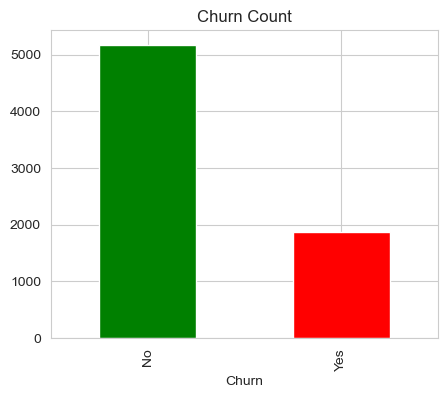

26.536987079369588 % churn rate


In [16]:
plt.figure(figsize=(5,4))
df["Churn"].value_counts().plot(kind="bar", color=["green","red"])
plt.title("Churn Count")
plt.savefig("charts/1_churn_count.png", bbox_inches="tight")
plt.show()
print(df["ChurnFlag"].mean()*100, "% churn rate")

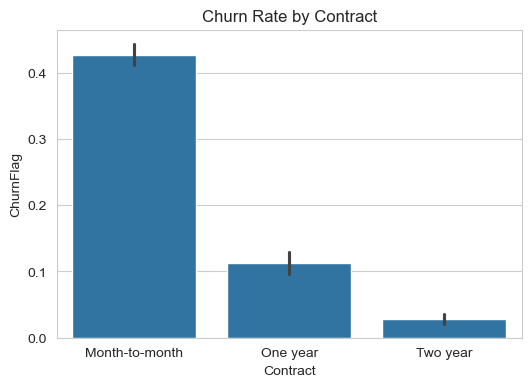

In [17]:
plt.figure(figsize=(6,4))
sns.barplot(x="Contract", y="ChurnFlag", data=df)
plt.title("Churn Rate by Contract")
plt.savefig("charts/2_contract.png", bbox_inches="tight")
plt.show()

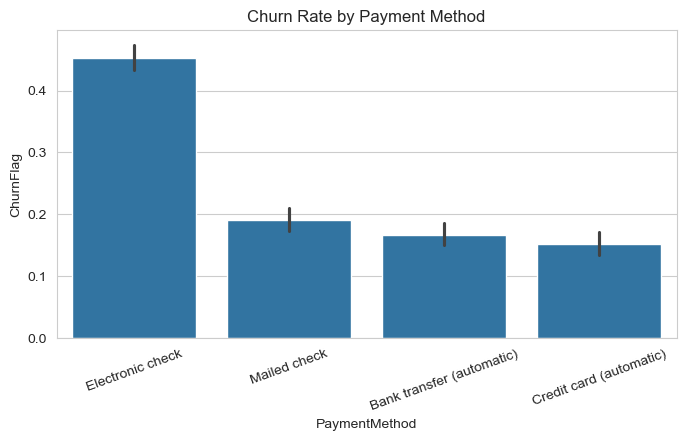

In [18]:
plt.figure(figsize=(8,4))
sns.barplot(x="PaymentMethod", y="ChurnFlag", data=df)
plt.xticks(rotation=20)
plt.title("Churn Rate by Payment Method")
plt.savefig("charts/3_payment.png", bbox_inches="tight")
plt.show()

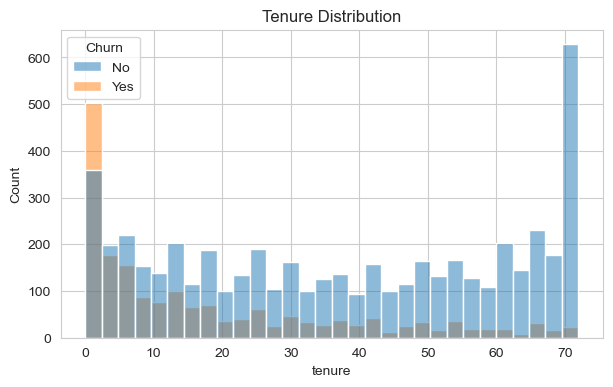

In [19]:
plt.figure(figsize=(7,4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30)
plt.title("Tenure Distribution")
plt.savefig("charts/4_tenure.png", bbox_inches="tight")
plt.show()

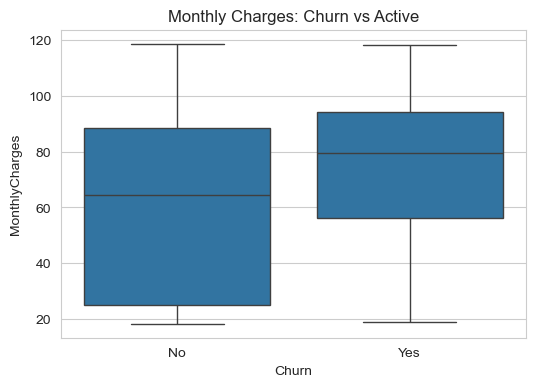

In [20]:
plt.figure(figsize=(6,4))
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Monthly Charges: Churn vs Active")
plt.savefig("charts/5_monthly.png", bbox_inches="tight")
plt.show()

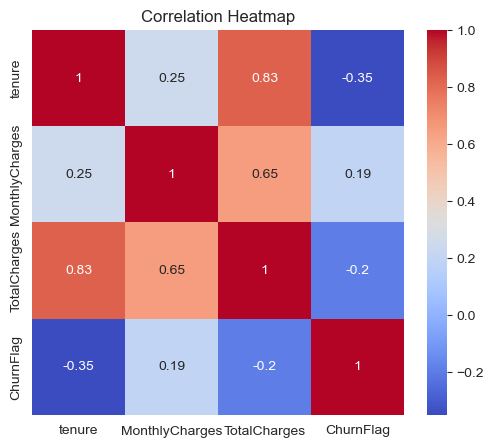

In [21]:
plt.figure(figsize=(6,5))
sns.heatmap(df[["tenure","MonthlyCharges","TotalCharges","ChurnFlag"]].corr(),
            annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.savefig("charts/6_heatmap.png", bbox_inches="tight")
plt.show()

In [22]:
def segment(r):
    if r["MonthlyCharges"] > 70 and r["tenure"] > 24 and r["ChurnFlag"] == 0:
        return "High-Value Loyal"
    elif r["MonthlyCharges"] > 70 and r["Contract"] == "Month-to-month":
        return "High-Value At-Risk"
    elif r["tenure"] <= 12:
        return "New"
    elif r["tenure"] > 48:
        return "Long-Term"
    else:
        return "Low-Revenue"

df["Segment"] = df.apply(segment, axis=1)

seg = df.groupby("Segment").agg(
    Customers=("customerID","count"),
    AvgMonthly=("MonthlyCharges","mean"),
    ChurnRate=("ChurnFlag","mean")
).round(2)
seg["ChurnRate"] = (seg["ChurnRate"]*100).round(1)
seg

,Customers,AvgMonthly,ChurnRate
Segment,,,
High-Value At-Risk,1589,86.22,70.0
High-Value Loyal,1775,93.32,0.0
Long-Term,956,45.63,14.0
Low-Revenue,1393,41.88,13.0
New,1330,38.73,34.0


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)


drop_cols = ["customerID", "Churn", "ChurnFlag", "Segment", "RiskGroup"]
X = df.drop(columns=drop_cols)
y = df["ChurnFlag"]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])
print(X_train.shape, X_test.shape)

(5634, 21) (1409, 21)


In [24]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=42, n_jobs=-1)
}

fitted = {}
rows = []
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC_AUC": roc_auc_score(y_test, prob)
    })

results = pd.DataFrame(rows).round(3)
results.to_csv("data/model_comparison.csv", index=False)
results

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.734,0.499,0.797,0.614,0.842
1,Random Forest,0.784,0.621,0.481,0.542,0.824


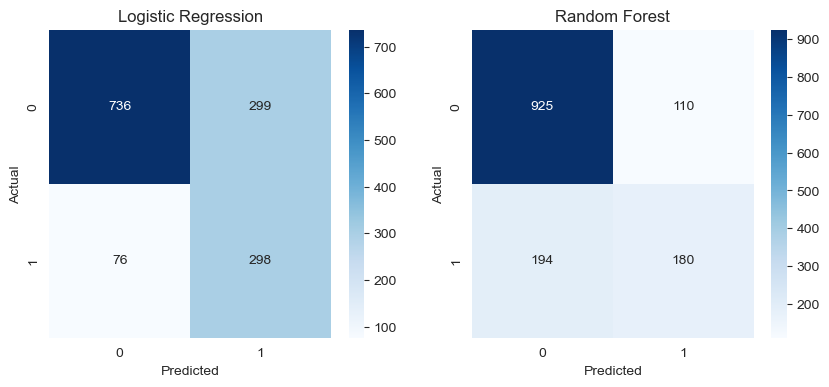

In [25]:
cm_rows = []
for name, pipe in fitted.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pipe.predict(X_test)).ravel()
    cm_rows.append({"Model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
cm_df = pd.DataFrame(cm_rows)
cm_df.to_csv("data/confusion_matrix.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    sns.heatmap(confusion_matrix(y_test, pipe.predict(X_test)),
                annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.savefig("charts/7_confusion.png", bbox_inches="tight")
plt.show()

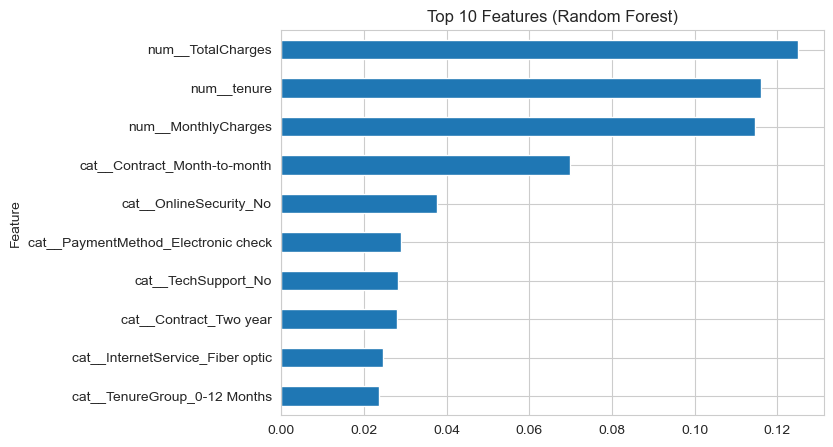

,Feature,Importance
2,num__TotalCharges,0.125054
0,num__tenure,0.116162
1,num__MonthlyCharges,0.114750
37,cat__Contract_Month-to-month,0.069952
19,cat__OnlineSecurity_No,0.037776
44,cat__PaymentMethod_Electronic check,0.028934
28,cat__TechSupport_No,0.028223
39,cat__Contract_Two year,0.027973
17,cat__InternetService_Fiber optic,0.024563
46,cat__TenureGroup_0-12 Months,0.023711


In [26]:
rf = fitted["Random Forest"]
names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.DataFrame({"Feature": names,
                    "Importance": rf.named_steps["model"].feature_importances_})
imp = imp.sort_values("Importance", ascending=False)
imp.to_csv("data/feature_importance.csv", index=False)

imp.head(10).plot(kind="barh", x="Feature", y="Importance", figsize=(7,5), legend=False)
plt.gca().invert_yaxis()
plt.title("Top 10 Features (Random Forest)")
plt.savefig("charts/8_importance.png", bbox_inches="tight")
plt.show()
imp.head(10)

In [27]:
best = fitted["Logistic Regression"]   
df["ChurnProb"] = best.predict_proba(X)[:, 1]
df["ExpectedRevenueAtRisk"] = df["ChurnProb"] * df["MonthlyCharges"]

df["RiskCategory"] = pd.cut(df["ChurnProb"], bins=[-0.01, 0.3, 0.6, 1.0],
                            labels=["Low", "Medium", "High"])
df[["customerID", "ChurnProb", "ExpectedRevenueAtRisk", "RiskCategory"]].head()

,customerID,ChurnProb,ExpectedRevenueAtRisk,RiskCategory
0,7590-VHVEG,0.805683,24.049648,High
1,5575-GNVDE,0.104462,5.949123,Low
2,3668-QPYBK,0.560577,30.187056,Medium
3,7795-CFOCW,0.075285,3.184563,Low
4,9237-HQITU,0.867305,61.318487,High


In [28]:
total_mrr = df["MonthlyCharges"].sum()
churned_mrr = df.loc[df["ChurnFlag"] == 1, "MonthlyCharges"].sum()

active = df[df["ChurnFlag"] == 0].copy()
expected_risk = active["ExpectedRevenueAtRisk"].sum()

print("Total Monthly Revenue:", round(total_mrr, 2))
print("Revenue from Churned customers:", round(churned_mrr, 2))
print("Expected Revenue at Risk (active):", round(expected_risk, 2))

Total Monthly Revenue: 456116.6
Revenue from Churned customers: 139130.85
Expected Revenue at Risk (active): 114171.1


In [29]:
top20 = active.sort_values("ExpectedRevenueAtRisk", ascending=False).head(20)
top20 = top20[["customerID", "Contract", "tenure", "MonthlyCharges",
               "ChurnProb", "ExpectedRevenueAtRisk"]]
top20.to_csv("data/top20_at_risk.csv", index=False)
top20

,customerID,Contract,tenure,MonthlyCharges,ChurnProb,ExpectedRevenueAtRisk
1568,3292-PBZEJ,Month-to-month,11,111.40,0.896463,99.865955
2387,6734-GMPVK,Month-to-month,5,105.30,0.898588,94.621281
1719,2081-VEYEH,Month-to-month,3,107.95,0.873543,94.298989
2582,7145-FEJWU,Month-to-month,12,105.30,0.886602,93.359159
678,5760-IFJOZ,Month-to-month,3,107.95,0.862896,93.149673
3159,5150-ITWWB,Month-to-month,3,94.85,0.948283,89.944668
574,6030-REHUX,Month-to-month,28,110.85,0.808008,89.567643
4701,5956-YHHRX,Month-to-month,21,104.35,0.856121,89.336270
6963,9547-ITEFG,Month-to-month,9,102.60,0.867787,89.034955
3270,4132-KALRO,Month-to-month,4,100.85,0.880356,88.783892


In [30]:
risk_contract = active.groupby("Contract")["ExpectedRevenueAtRisk"].sum().round(2).reset_index()
risk_segment = active.groupby("Segment")["ExpectedRevenueAtRisk"].sum().round(2).reset_index()
risk_contract.to_csv("data/risk_by_contract.csv", index=False)
risk_segment.to_csv("data/risk_by_segment.csv", index=False)
print(risk_contract)
print(risk_segment)

         Contract  ExpectedRevenueAtRisk
0  Month-to-month               82171.01
1        One year               22596.85
2        Two year                9403.24
              Segment  ExpectedRevenueAtRisk
0  High-Value At-Risk               30734.86
1    High-Value Loyal               52338.23
2           Long-Term                2651.92
3         Low-Revenue               11364.91
4                 New               17081.18


In [31]:
scen = pd.DataFrame({
    "Reduction": ["10%", "20%", "30%"],
    "RetainedMonthlyRevenue": [round(expected_risk * p, 2) for p in (0.10, 0.20, 0.30)]
})
scen["RetainedAnnualRevenue"] = (scen["RetainedMonthlyRevenue"] * 12).round(2)
scen.to_csv("data/scenarios.csv", index=False)
scen

,Reduction,RetainedMonthlyRevenue,RetainedAnnualRevenue
0,10%,11417.11,137005.32
1,20%,22834.22,274010.64
2,30%,34251.33,411015.96


In [32]:

top100 = active.sort_values("ExpectedRevenueAtRisk", ascending=False).head(100)
top100[["customerID", "Contract", "tenure", "MonthlyCharges",
        "ChurnProb", "ExpectedRevenueAtRisk"]].to_csv("data/top100_customers.csv", index=False)

saving_top = top100["ExpectedRevenueAtRisk"].sum() * 0.15


rng = np.random.default_rng(42)
rand_sav = [active.sample(100, random_state=int(s))["ExpectedRevenueAtRisk"].sum() * 0.15
            for s in rng.integers(0, 100000, 500)]
saving_rand = float(np.mean(rand_sav))

camp = pd.DataFrame({
    "Method": ["Top 100 (our ranking)", "Random 100 (avg of 500 tries)"],
    "MonthlySaving": [round(saving_top, 2), round(saving_rand, 2)]
})
camp["AnnualSaving"] = (camp["MonthlySaving"] * 12).round(2)
camp.to_csv("data/campaign_comparison.csv", index=False)
print(camp)
print("Top 100 is", round(saving_top / saving_rand, 1), "x better than random")

                          Method  MonthlySaving  AnnualSaving
0          Top 100 (our ranking)        1254.95      15059.40
1  Random 100 (avg of 500 tries)         328.62       3943.44
Top 100 is 3.8 x better than random


In [33]:
df.to_csv("data/powerbi_customers.csv", index=False)
print("Saved", df.shape)

Saved (7043, 29)


In [34]:
print("=== Segment with highest churn ===")
print(seg)

print("\n=== Churn by Contract ===")
print((df.groupby("Contract")["ChurnFlag"].mean()*100).round(1))

print("\n=== Churn by TenureGroup ===")
print((df.groupby("TenureGroup")["ChurnFlag"].mean()*100).round(1))

print("\n=== Churn by PaymentMethod ===")
print((df.groupby("PaymentMethod")["ChurnFlag"].mean()*100).round(1))

print("\n=== Top 5 features ===")
print(imp.head(5))

print("\n=== Model comparison ===")
print(results)

print("\n=== Revenue ===")
print("Total MRR:", round(total_mrr,2))
print("Churned MRR:", round(churned_mrr,2))
print("Expected revenue at risk:", round(expected_risk,2))

print("\n=== Scenarios ===")
print(scen)

print("\n=== Campaign ===")
print(camp)

=== Segment with highest churn ===
                    Customers  AvgMonthly  ChurnRate
Segment                                             
High-Value At-Risk       1589       86.22       70.0
High-Value Loyal         1775       93.32        0.0
Long-Term                 956       45.63       14.0
Low-Revenue              1393       41.88       13.0
New                      1330       38.73       34.0

=== Churn by Contract ===
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: ChurnFlag, dtype: float64

=== Churn by TenureGroup ===
TenureGroup
0-12 Months     47.4
13-24 Months    28.7
25-48 Months    20.4
49+ Months       9.5
Name: ChurnFlag, dtype: float64

=== Churn by PaymentMethod ===
PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: ChurnFlag, dtype: float64

=== Top 5 features ===
                         Feature  Importance
2              n